****PRACTICA FINAL IA (YouTube Trending Videos)****

**Preprocesamiento**

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import pickle as pkl

Actualizamos la categoria de nuestro fichero csv en base a los datos que tenemos en el fichero JSON.

In [2]:
def actualizacion_categoria_pais(ruta_csv, ruta_json, nombre_pais):

    """Función que actualiza la category_id del Csv reemplazando por el valor string asignado en el fichero json y añade columna con el pais."""
    
    dfjson = pd.read_json(ruta_json)#en vez de leer linea por linea, empaqueta todo el json
    dfjson_aplanado = pd.json_normalize(dfjson['items'])
    dfjson_items = pd.DataFrame({'json_id': dfjson_aplanado['id'].astype(str),'category': dfjson_aplanado['snippet.title']})
    
    dfcsv = pd.read_csv(ruta_csv, encoding='ISO-8859-1')
    dfcsv['category_id'] = dfcsv['category_id'].astype(str)
    
    df_final = pd.merge(dfcsv, dfjson_items, left_on='category_id', right_on='json_id', how='left')
    
    df_final = df_final.drop(columns=['json_id', 'category_id'])

    df_final['pais'] = nombre_pais#creamos la columna pais 
                
    return df_final

In [3]:
paises = {"CA":"Canadá","DE":"Alemania","FR":"Francia","GB":"Gran Bretaña","IN":"India","JP":"Japón","KR":"Corea","MX":"Mexico","RU":"Rusia","US":"USA"}

In [4]:
dataframe_por_pais = (actualizacion_categoria_pais(f"{c}videos.csv", f"{c}_category_id.json", nombre) for c, nombre in paises.items())

Unificamos todos los dataframes

In [5]:
dataframe_final = pd.concat(dataframe_por_pais, ignore_index=True)

Confirmamos que en nuestro dataframe final hay registros de todos los paises.

In [6]:
dataframe_final.pais.value_counts()

pais
USA             40949
Canadá          40881
Alemania        40840
Rusia           40739
Francia         40724
Mexico          40451
Gran Bretaña    38916
India           37352
Corea           34567
Japón           20523
Name: count, dtype: int64

title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

In [7]:
dataframe_final.shape

(375942, 17)

Procedemos a quitar los duplicados.

In [8]:
dataframe_final.drop_duplicates(inplace=True)

In [9]:
dataframe_final.shape

(363372, 17)

Se eliminan alrededor de 12000 duplicados

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador 

Las columnas video_id, description y thumbnail_link  no tiene ningún tipo de información que nos pueda ayudar. Las eliminamos.

In [10]:
dataframe_final.drop(["video_id", "thumbnail_link", "description"], axis=1, inplace=True)

In [11]:
dataframe_final.shape

(363372, 14)

In [12]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 363372 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           363372 non-null  object
 1   title                   363372 non-null  object
 2   channel_title           363372 non-null  object
 3   publish_time            363372 non-null  object
 4   tags                    363372 non-null  object
 5   views                   363372 non-null  int64 
 6   likes                   363372 non-null  int64 
 7   dislikes                363372 non-null  int64 
 8   comment_count           363372 non-null  int64 
 9   comments_disabled       363372 non-null  bool  
 10  ratings_disabled        363372 non-null  bool  
 11  video_error_or_removed  363372 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    363372 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vemos en category que hay algún nulo. Procedemos a eliminarlos

In [13]:
dataframe_final.dropna(inplace=True)

In [14]:
dataframe_final.shape

(360662, 14)

In [15]:
dataframe_final.info()#Confirmamos que se han quitado todos los nulos.

<class 'pandas.core.frame.DataFrame'>
Index: 360662 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           360662 non-null  object
 1   title                   360662 non-null  object
 2   channel_title           360662 non-null  object
 3   publish_time            360662 non-null  object
 4   tags                    360662 non-null  object
 5   views                   360662 non-null  int64 
 6   likes                   360662 non-null  int64 
 7   dislikes                360662 non-null  int64 
 8   comment_count           360662 non-null  int64 
 9   comments_disabled       360662 non-null  bool  
 10  ratings_disabled        360662 non-null  bool  
 11  video_error_or_removed  360662 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    360662 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vamos con title y channel title. Vemos que es un video de tendencias por lo que podria suceder que el mismo video fuera tendencia varios dias 
y por tantos los datos pudieran estar duplicados pero el drop_duplicates no haya funcionado porque las variables numéricas sean diferentes.

In [16]:
df_duplicados_ejemplos = dataframe_final[dataframe_final.duplicated(subset=["title", "channel_title"])]#keep false para valores unicos sin repetir duplicados
df_duplicados_ejemplos.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
200,17.15.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",2649977,193479,3496,17846,False,False,False,Comedy,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
216,17.15.11,STRANGER JOKES : Jokes de Papa avec les teens ...,"Le Jeu, C'est SÃ©rieux",2017-11-13T15:48:57.000Z,"Stranger Jokes|""Jokes de Papa""|""Stranger Thing...",443131,27026,491,746,False,False,False,Comedy,Canadá
218,17.15.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,2017-11-13T17:13:01.000Z,SHANtell martin,2188675,88100,7150,24225,False,False,False,People & Blogs,Canadá
219,17.15.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",4326684,167696,6730,9265,False,False,False,Comedy,Canadá


Los registros que nos aparecen son registros que tienen más de un registro con el mismo nombre y canal. Veamos un ejemplo:

In [17]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. BeyoncÃ©") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
0,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,False,False,False,Music,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
498,17.16.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",22702386,869304,50018,123235,False,False,False,Music,Canadá
791,17.17.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania


Vemos que hay columnas repetidas en las que como pasa aquí fue trending en varias ocasiones. Haremos filtrado y dejaremos un valor único por país teniendo en cuenta principalmente la variable views, ya que a priori a mas alta dicha variable mas likes, dislikes y commments debería haber ya que el formato youtube va acumulando cada dia dichos items. Tenemos en cuenta país ya que un mismo vídeo puede ser tendencia en dos o más países y de cara a nuestro modelo puede ser interesante.

In [18]:
dataframe_final.sort_values(by="views", ascending=False, inplace=True)

dataframe_final.drop_duplicates(subset=["channel_title", "title", "pais"],keep="first",inplace=True)

Una vez ordenados los datos y quitados los duplicados, confirmamos que efectivamente nos ha dejado un valor único por país y si habiendo varios regitros iguales el que más views tiene (ver Canadá por ejemplo)

In [19]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. BeyoncÃ©") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
125227,17.27.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",39235314,1044324,63815,137383,False,False,False,Music,Gran Bretaña
335988,17.18.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",26448434,911883,53873,127481,False,False,False,Music,USA
791,17.17.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania
81791,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem""|""Walk""|""On""|""Water""|""Aftermath/Shady/I...",17158579,787425,43420,125882,False,False,False,Music,Francia
219394,17.14.11,Eminem - Walk On Water (Audio) ft. BeyoncÃ©,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787426,43420,125882,False,False,False,Music,Corea


In [20]:
dataframe_final.shape#Aligeramos el peso del dataframe.

(207525, 14)

In [21]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           207525 non-null  object
 1   title                   207525 non-null  object
 2   channel_title           207525 non-null  object
 3   publish_time            207525 non-null  object
 4   tags                    207525 non-null  object
 5   views                   207525 non-null  int64 
 6   likes                   207525 non-null  int64 
 7   dislikes                207525 non-null  int64 
 8   comment_count           207525 non-null  int64 
 9   comments_disabled       207525 non-null  bool  
 10  ratings_disabled        207525 non-null  bool  
 11  video_error_or_removed  207525 non-null  bool  
 12  category                207525 non-null  object
 13  pais                    207525 non-null  object
dtypes: bool(3), int64(4), object(7)
memo

Procedemos a pasar trending date y publish time a formato datetime y creamos una columna que indica los numeros de días que pasaron desde que se publicó hasta que fue trending. Una vez se ha creado la columna, eliminamos ambas columnas.

In [22]:
dataframe_final["trending_date"] = pd.to_datetime(dataframe_final["trending_date"], format="%y.%d.%m", errors="coerce").dt.floor('D')


dataframe_final["publish_time"] = pd.to_datetime(dataframe_final["publish_time"], errors="coerce").dt.tz_localize(None).dt.floor('D')


dataframe_final["dias_desde_publicacion"] = (dataframe_final["trending_date"] - dataframe_final["publish_time"]).dt.days.clip(lower=0)



In [23]:
dataframe_final.drop(["trending_date","publish_time"], axis=1, inplace=True)

In [24]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"Bad Bunny|""Amorfoda""|""Dura""|""Daddy Yankee""|""Oz...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,36
156905,"Te Bote Remix - Casper, Nio GarcÃ­a, Darell, N...",Flow La Movie,"Te Bote|""Te Bote Remix""|""Flow La Movie""|""Ozuna...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,37
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"Bad|""Bunny""|""Bad Bunny""|""Video Oficial""|""Music...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,36
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"Ozuna|""Reggaeton""|""Odisea""|""Odisea The Album""|...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,30
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"Childish Gambino|""Rap""|""This Is America""|""mcDJ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,36


Vamos a modificar los formatos de cada columna. Comenzaremos con title de tipo string. Procedemos a quitar los espacios 
y los posibles saltos de línea al introducir el nombre del title.

In [25]:
dataframe_final["title"] = (dataframe_final["title"].str.strip().str.split().str.join(" "))

Realizamos la misma transformación en channel_title:

In [26]:
dataframe_final["channel_title"] = (dataframe_final["channel_title"].str.strip().str.split().str.join(" "))

En el caso de tags además de los espacios en blanco, debemos de quitar "|" para que el modelo pueda leerlo mejor. 
Metemos los datos en una lista.

In [27]:
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split().str.join(" "))
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split("|", regex=False))

In [28]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, ""Amorfoda"", ""Dura"", ""Daddy Yankee""...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,36
156905,"Te Bote Remix - Casper, Nio GarcÃ­a, Darell, N...",Flow La Movie,"[Te Bote, ""Te Bote Remix"", ""Flow La Movie"", ""O...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,37
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, ""Bunny"", ""Bad Bunny"", ""Video Oficial"", ""...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,36
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, ""Reggaeton"", ""Odisea"", ""Odisea The Alb...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,30
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, ""Rap"", ""This Is America"", ""...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,36


Limpio el dataset, lo guardamos en formato pickle y  pasamos al análisis exploratorio

In [29]:
dataframe_final.to_pickle("dataframe_final_limpio.pkl")

**Analisis exploratorio**

A continuación vamos a ver un poco los datos que tenemos después de procesar nuestro df. Para esta parte lo pasamos a pandas.

In [30]:
df = pd.read_pickle("dataframe_final_limpio.pkl")

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   title                   207525 non-null  object
 1   channel_title           207525 non-null  object
 2   tags                    207525 non-null  object
 3   views                   207525 non-null  int64 
 4   likes                   207525 non-null  int64 
 5   dislikes                207525 non-null  int64 
 6   comment_count           207525 non-null  int64 
 7   comments_disabled       207525 non-null  bool  
 8   ratings_disabled        207525 non-null  bool  
 9   video_error_or_removed  207525 non-null  bool  
 10  category                207525 non-null  object
 11  pais                    207525 non-null  object
 12  dias_desde_publicacion  207525 non-null  int64 
dtypes: bool(3), int64(5), object(5)
memory usage: 18.0+ MB


In [32]:
matriz_correlacion = df.corr(numeric_only=True)#sacamos la matriz de correlacion para vaer relacion de las variables numéricas

In [33]:
print(matriz_correlacion)

                           views     likes  dislikes  comment_count  \
views                   1.000000  0.747095  0.442746       0.528759   
likes                   0.747095  1.000000  0.429676       0.803652   
dislikes                0.442746  0.429676  1.000000       0.637617   
comment_count           0.528759  0.803652  0.637617       1.000000   
comments_disabled      -0.006558 -0.022285 -0.006149      -0.022113   
ratings_disabled       -0.011216 -0.027856 -0.011366      -0.015297   
video_error_or_removed  0.006401  0.007036  0.002517       0.003513   
dias_desde_publicacion  0.009653  0.004343  0.001854       0.001563   

                        comments_disabled  ratings_disabled  \
views                           -0.006558         -0.011216   
likes                           -0.022285         -0.027856   
dislikes                        -0.006149         -0.011366   
comment_count                   -0.022113         -0.015297   
comments_disabled                1.000000    

Conclusiones:  

Likes y comment_count: Si hay un like, suele haber un comentario de manera generalizada.

Views y likes: A más visualizaciones más likes. Por lo tanto views, likes y comment_count suelen ir de la mano.

Dislikes con views, likes y comment_count: Cuanto más se ve el video, más posibles dislikes puede provocar y por tanto, mas comentarios a modo de hate.

In [34]:
df.describe()

,views,likes,dislikes,comment_count,dias_desde_publicacion
count,2.075250e+05,2.075250e+05,2.075250e+05,2.075250e+05,207525.000000
mean,5.340433e+05,1.626300e+04,9.406069e+02,2.005660e+03,4.020870
std,3.279155e+06,8.822365e+04,1.250509e+04,1.409846e+04,62.406812
min,1.530000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.581900e+04,3.750000e+02,2.300000e+01,6.000000e+01,1.000000
50%,9.312400e+04,1.732000e+03,9.400000e+01,2.710000e+02,1.000000
75%,3.247840e+05,7.470000e+03,3.720000e+02,1.041000e+03,2.000000
max,4.245389e+08,5.613827e+06,1.944971e+06,1.626501e+06,4215.000000


Podemos ver que los valores máximos y minimos distorsionan mucho con respecto a la media y si intentamos sacar outliers, vemos 
que hay en las variables views, likes, dislikes, comment_count y dias desde publicación. Esto es debido a la viralidad que se puede dar con cierto vídeo. Vamos a representar los outliers de views ya que como vimos anteriormente a partir de ella el resto de outliers que hemos visto también pueden aumentar dada su gran relación.

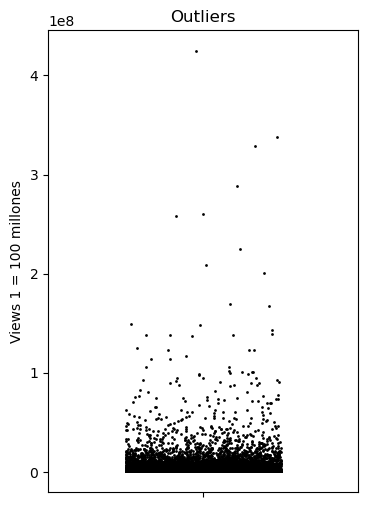

In [35]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1 #Rango intercuantílico
limite_outliers = Q3 + (1.5 * IQR)
df_outliers = df[df["views"] > limite_outliers]

plt.figure(figsize=(4, 6))
sns.stripplot(y=df_outliers["views"], color="black", jitter=0.25,size=2)

plt.title("Outliers")
plt.ylabel("Views 1 = 100 millones")
plt.show()

Vemos claramente los outliers y de cara al EDA los dejamos ya que según que planteamiento puede ser bueno quitarlos o no.

**Analisis univariado de variables categoricas**

In [36]:
df.category.value_counts(normalize=True)

category
Entertainment            0.295540
People & Blogs           0.172495
News & Politics          0.114208
Sports                   0.075157
Music                    0.067139
Comedy                   0.063496
Film & Animation         0.052818
Howto & Style            0.051295
Gaming                   0.029828
Education                0.021183
Science & Technology     0.019718
Autos & Vehicles         0.016894
Pets & Animals           0.012191
Travel & Events          0.004563
Shows                    0.003315
Nonprofits & Activism    0.000072
Movies                   0.000072
Trailers                 0.000014
Name: proportion, dtype: float64

Vemos que más de la mitad de los videos son de la categoría Entertainment, People & Blogs y News & Politics.

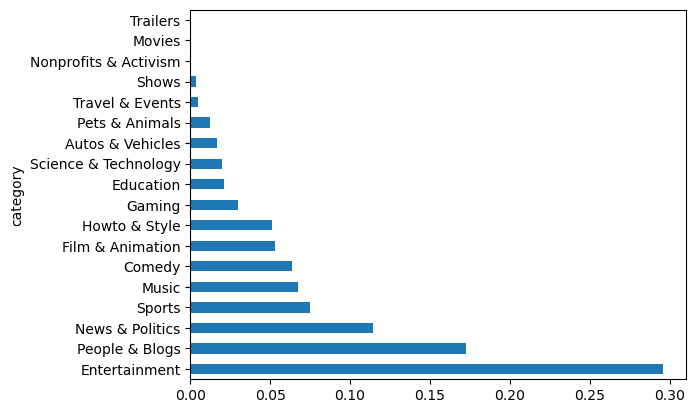

In [37]:
df.category.value_counts(normalize=True).plot.barh()
plt.show()

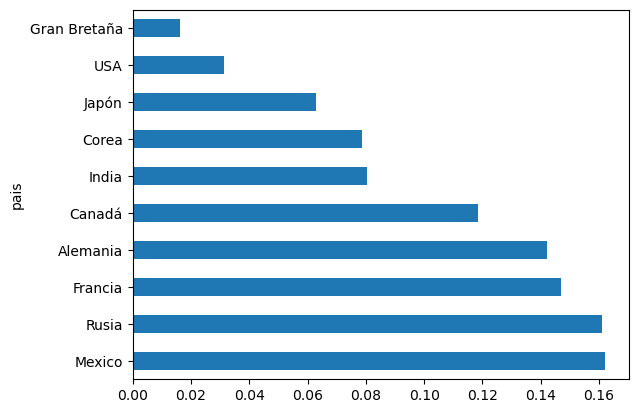

In [38]:
df.pais.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que lo datos se centran sobre todo en los paises Rusia, Mexico, Alemania, Francia y Canada

In [39]:
df['comments_disabled'].value_counts()

comments_disabled
False    202629
True       4896
Name: count, dtype: int64

In [40]:
df['ratings_disabled'].value_counts()

ratings_disabled
False    202892
True       4633
Name: count, dtype: int64

In [41]:
df['video_error_or_removed'].value_counts()

video_error_or_removed
False    207420
True        105
Name: count, dtype: int64

In [42]:
df.drop('video_error_or_removed', axis=1, inplace=True)

Vemos que no tiene ningún valor esta variable por lo que la eliminamos ahora aquí e insertamos la actualización el fichero preprocess.

In [43]:
df.sort_values(by='views', ascending=False).head(10)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, ""Amorfoda"", ""Dura"", ""Daddy Yankee""...",424538912,2818771,149275,99380,False,False,Music,Gran Bretaña,36
156905,"Te Bote Remix - Casper, Nio GarcÃ­a, Darell, N...",Flow La Movie,"[Te Bote, ""Te Bote Remix"", ""Flow La Movie"", ""O...",337621571,2581961,166549,113564,False,False,Music,Gran Bretaña,37
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, ""Bunny"", ""Bad Bunny"", ""Video Oficial"", ""...",328860380,3823879,215530,225216,False,False,Music,Gran Bretaña,36
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, ""Reggaeton"", ""Odisea"", ""Odisea The Alb...",288811992,1618180,151147,67506,False,False,Music,Gran Bretaña,30
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, ""Rap"", ""This Is America"", ""...",259721696,5444541,379862,553371,False,False,Music,Gran Bretaña,36
148381,Drake - Godâs Plan,DrakeVEVO,"[Drake new music, ""Drake Gods Plan"", ""Drake Go...",258164991,4737873,117198,301756,False,False,Music,Gran Bretaña,36
373540,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, ""Rap"", ""This Is America"", ""...",225211923,5023450,343541,517232,False,False,Music,USA,27
158165,Ariana Grande - No Tears Left To Cry,ArianaGrandeVevo,"[Ariana, ""Grande"", ""No"", ""Tears"", ""Left"", ""To""...",208876887,3394437,150086,259613,False,False,Music,Gran Bretaña,36
158168,"Becky G, Natti Natasha - Sin Pijama (Official ...",BeckyGVEVO,"[Becky G, ""Natti Natasha"", ""Natti Natasha Musi...",200862743,1668418,142569,97826,False,False,Music,Gran Bretaña,36
130634,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,"[Rewind, ""Rewind 2017"", ""youtube rewind 2017"",...",169884583,3312868,1753274,845233,False,False,Entertainment,Gran Bretaña,18


Vemos que hay videos que han sido tendencia en diferentes países.

**Analisis bivariado de variables categoricas**

In [44]:
df.pivot_table(index="pais", columns="category", values="views")

category,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Movies,Music,News & Politics,Nonprofits & Activism,People & Blogs,Pets & Animals,Science & Technology,Shows,Sports,Trailers,Travel & Events
pais,,,,,,,,,,,,,,,,,,
Alemania,1.934430e+05,6.370840e+05,144247.965465,4.317013e+05,5.769994e+05,3.500935e+05,299676.137482,2289027.0,2.024636e+06,251877.822710,NaN,3.046419e+05,2.919468e+05,4.782260e+05,4.761774e+05,5.810094e+05,8804.0,1.406850e+05
Canadá,4.816398e+05,8.724318e+05,459409.744538,7.317288e+05,9.819128e+05,7.185641e+05,663049.498428,5661965.0,3.167182e+06,307902.629232,NaN,5.765851e+05,5.519081e+05,9.654540e+05,5.817826e+05,8.038909e+05,NaN,3.963594e+05
Corea,1.070090e+05,3.513303e+05,118163.835443,4.361690e+05,4.645750e+05,2.492368e+05,382025.701887,NaN,1.774032e+06,134716.433151,NaN,1.941641e+05,1.925386e+05,2.568550e+06,1.082023e+05,6.916621e+05,19845.0,2.669650e+05
Francia,6.090521e+04,3.730210e+05,129644.401421,3.449008e+05,3.556891e+05,2.414941e+05,182430.649468,101141.3,1.144151e+06,117205.640959,NaN,1.904643e+05,1.643618e+05,4.041146e+05,5.236306e+05,4.004828e+05,9804.0,5.457332e+04
Gran Bretaña,1.457632e+06,1.967056e+06,780772.000000,2.567087e+06,2.427073e+06,8.232446e+05,459653.915000,NaN,1.272255e+07,773944.250000,NaN,1.245253e+06,8.816329e+05,1.993358e+06,1.709880e+06,1.040113e+06,NaN,1.071762e+06
India,3.332654e+05,7.089324e+05,92438.020910,5.766691e+05,1.778204e+06,3.227187e+06,822677.317427,3862190.0,2.076332e+06,297426.506202,NaN,4.474413e+05,1.317532e+06,6.594729e+05,6.513166e+05,1.410399e+06,NaN,1.929078e+05
Japón,6.246815e+04,3.672608e+05,83620.590361,2.504836e+05,2.547108e+05,1.487873e+05,116843.424184,NaN,6.492050e+05,118175.592513,NaN,1.264726e+05,4.913599e+04,8.949333e+05,NaN,2.668928e+05,NaN,1.111057e+05
Mexico,1.372178e+05,4.076255e+05,78476.971014,2.464302e+05,3.091245e+05,3.692244e+05,164914.949683,NaN,9.706897e+05,138016.199127,NaN,1.275828e+05,4.638445e+05,2.927205e+05,2.181200e+04,3.248669e+05,NaN,1.348224e+05
Rusia,2.097492e+05,2.889580e+05,53657.478064,3.157302e+05,1.625047e+05,1.926100e+05,168871.154684,100049.0,7.699724e+05,118024.212121,NaN,1.247756e+05,9.047947e+04,3.244303e+05,1.773477e+05,1.886925e+05,NaN,7.596964e+04


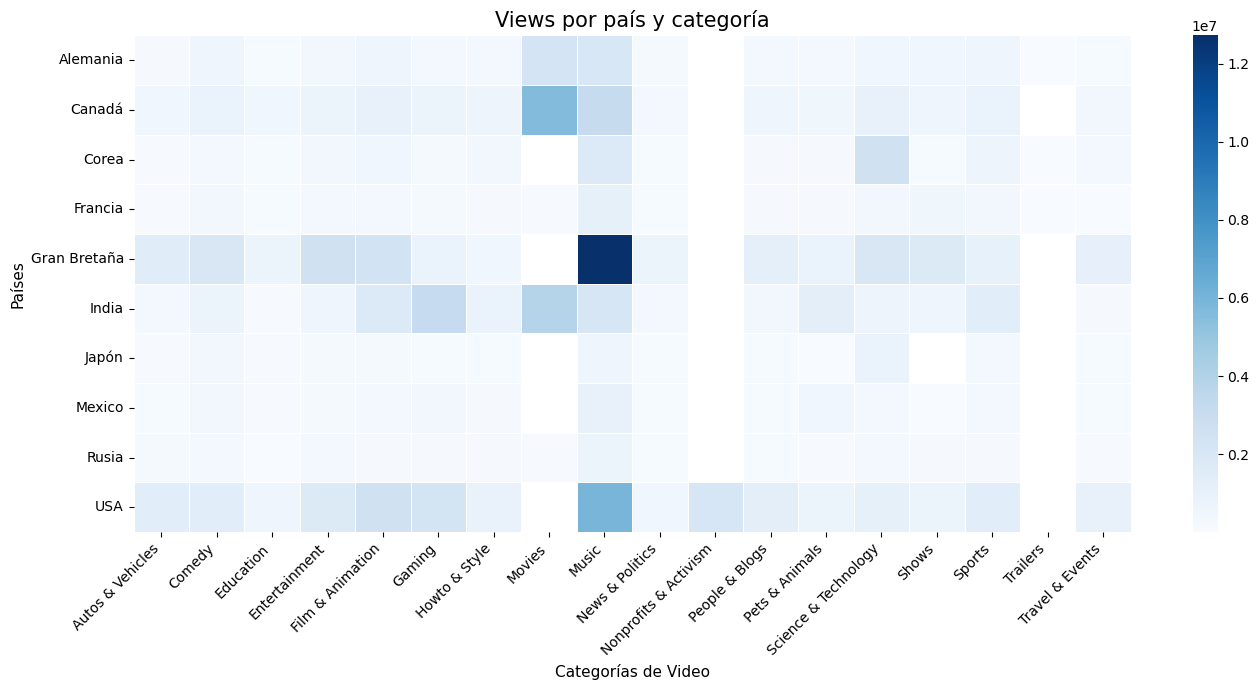

In [45]:
pivot_views = df.pivot_table(index="pais", columns="category", values="views")
plt.figure(figsize=(14, 7))

sns.heatmap(pivot_views, cmap="Blues", annot=False, linewidths=0.5)

plt.title("Views por país y categoría",fontsize=15)
plt.xlabel("Categorías de Video", fontsize=11)
plt.ylabel("Países", fontsize=11)
plt.xticks(rotation=45, ha="right") 

plt.tight_layout()
plt.show()

Vemos que las mayorias de visualizaciones se dan en Gran Bretaña y EEUU y que la categoría que más views suele tener es Music. El hecho de que un video sea de Gran Bretaña y de Musica puede ser relevante por ejemplo para el modelo, por lo que ambas categorías es bueno tenerlas en cuenta.

Vamos a desglosar comments_disabled	y ratings_disable. Estas dos variables la mayoría del tiempo son False ya que lo normal es querer que la gente comente y haga like o dislike a tus videos. Vamos a ver en cuantos casos desactivaron ambas variables.

In [46]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]

In [47]:
Desactivadas.shape

(1422, 12)

In [48]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]
Activadas = df[(df["comments_disabled"] == False) & (df["ratings_disabled"] == False)]

promedio_desactivadas = Desactivadas[["views"]].mean()# Calculamos los promedios de 'views' y 'likes' para ambos grupos
promedio_activadas = Activadas[["views"]].mean()

# 4. Juntamos ambos resultados en una pequeña tabla para comparar de reojo
comparativa_directa = pd.DataFrame({"Ambas Activadas": promedio_activadas, "Ambas Desactivadas": promedio_desactivadas}).T #Transponemos para que se cambien columnas y filas

print(comparativa_directa)

                            views
Ambas Activadas     542610.317715
Ambas Desactivadas  466137.777778


Vemos que cuando los comentarios y los ratings estan deshabilitados, suele haber mas visualizaciones por parte de los usuarios. Normalmente este tipo de sucesos se dan porque los videos suelen ser polémicos y los creadores de contenido quitan los comentarios y las interacciones.

Vimos que de media los videos suelen tardar unos 4 días en ser tendencia, aunque la mediana nos indica que suelen tardar alrededor de 1 dia. La dispersión es grande y se puede ver porque por ejemplo el vídeo máximo tardo 4215 dias en ser tendencia algo poco común.

Las conclusiones que podemos sacar son las siguientes:
1. Existe una relación clara entre los views, los coments y los likes/dislikes.
2. Entertainment, People & Blogs y News & Politics son las categorías que más destacan.
3. Un mismo vídeo puede ser viral en varios países.
4. Existe una relación directamente proporcional entre bloquear los comentarios y los ratings y las visualizaciones.
5. Cruzando datos vemos que los videos que más views han tenido son de Musica fundamentalmente en Reino Unido. Tanto Reino Unido como el tipo Musica muestran ser una de las piezas fundamentales sobre las que giran las visualizaciones.

A continuación vamos a pasar a realizar punto por punto lo solicitado en los modelos.

**Predecir categoria del video**

Vamos a utilizar los modelos conocidos pero en primer lugar vamos a rescatar el dataset limpio en formato parquet (lo hemos estado trabajando en pandas para el EDA), con el fin de ganar mayor rendimiento con Spark ML

In [102]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer #lo usamo para ensamblar
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [103]:
X = df[["views", "likes", "dislikes", "dias_desde_publicacion", "pais"]]
y = df["category"]

In [104]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

In [105]:
le = LabelEncoder()
ytrain_encoded = le.fit(ytrain)
ytrain = le.transform(ytrain)
ytest = le.transform(ytest)

In [106]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
#Definimos el encoder para las variables que sean categoricas, en este caso solo será pais.

In [107]:
logaritmo = FunctionTransformer(np.log1p)
scaler = StandardScaler()
#Definimos las transformaciones numéricas para tratar los outliers

Regresión logística

In [108]:
from sklearn.linear_model import LogisticRegression

In [109]:
lr = LogisticRegression()

Creamos un pipeline numérico para incluirlo en el ensamblador de Column Transformer ya que según el modelo los outliers pueden o no ser relevantes de quitar.

In [110]:
pipeline_num = Pipeline([('log', logaritmo),('scaler', scaler)])

In [111]:
preprocess_lr = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "dias_desde_publicacion"])])

In [112]:
Xtrain_listo_lr = preprocess_lr.fit_transform(Xtrain)
Xtest_listo_lr = preprocess_lr.transform(Xtest)

In [113]:
pipeline_lr = Pipeline(steps=[('preprocesamiento', preprocess_lr),
                              ('modelo', lr)])

In [114]:
pipeline_lr.fit(Xtrain, ytrain)#al aplicar anteriormente en preprocesamiento, ya no es necesario aplicar el fit_transform a Xtrain y Xtest, ya que el pipeline se encarga de ello.

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'dias_desde_publicacion'])])),
                ('modelo', LogisticRegression())])

Accuracy: 0.3295
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       657
           1       0.21      0.01      0.03      2670
           2       0.07      0.00      0.00       890
           3       0.35      0.81      0.48     12230
           4       0.11      0.00      0.00      2228
           5       0.00      0.00      0.00      1273
           6       0.10      0.01      0.02      2108
           7       0.00      0.00      0.00         2
           8       0.35      0.15      0.21      2723
           9       0.37      0.18      0.24      4838
          10       0.00      0.00      0.00         3
          11       0.28      0.33      0.30      7149
          12       0.14      0.03      0.05       509
          13       0.00      0.00      0.00       795
          14       0.00      0.00      0.00       158
          15       0.10      0.01      0.01      3089
          17       0.00      0.00      0.00       183

    accur

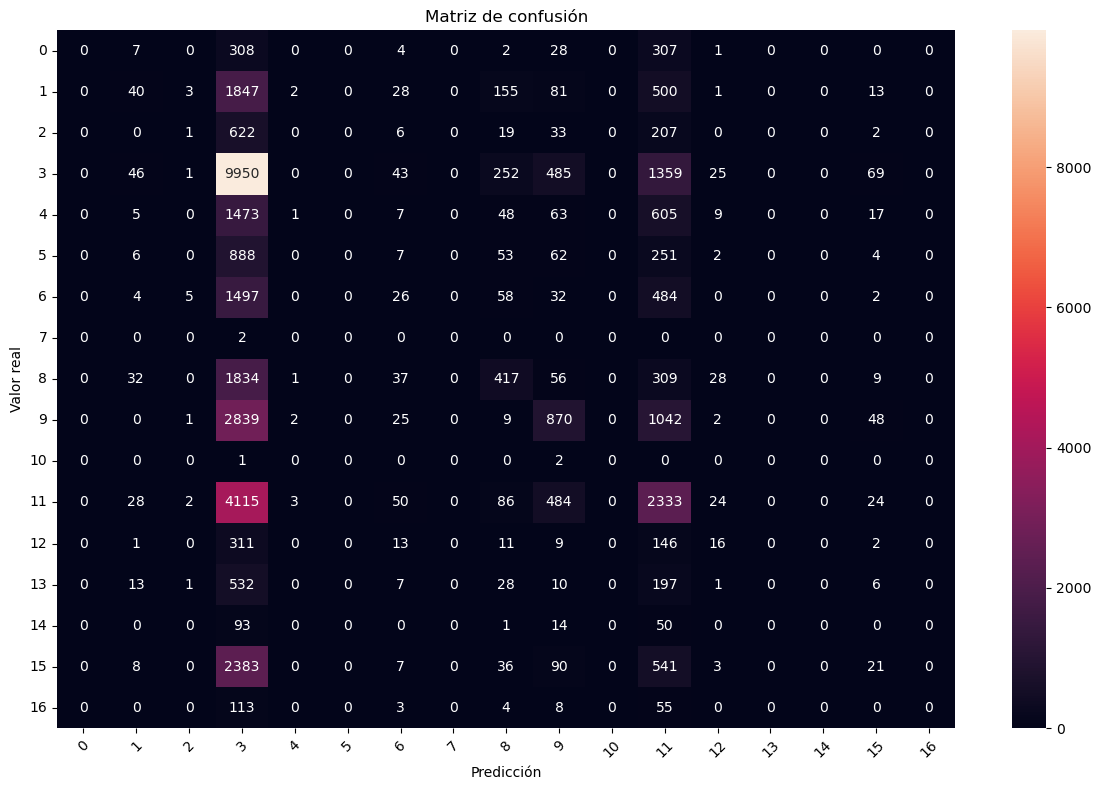

In [115]:
#Evaluación de la regresión logistica

y_pred_lr = pipeline_lr.predict(Xtest)

accuracy_lr = accuracy_score(ytest, y_pred_lr)
print(f"Accuracy: {accuracy_lr:.4f}")

print(classification_report(ytest, y_pred_lr, zero_division=0))

cm = confusion_matrix(ytest, y_pred_lr)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos en la matriz que el modelo está muy descompensado hacia las clases 3 y 11. Es posible que haya un desbalanceo en el cual haya clases más dominantes y clases con menos registros y por ello, el modelo tienda a no predecir nunca las no dominantes. Lo podemos ver a continuación.

In [79]:
df["category"].value_counts()

category
Entertainment            61332
People & Blogs           35797
News & Politics          23701
Sports                   15597
Music                    13933
Comedy                   13177
Film & Animation         10961
Howto & Style            10645
Gaming                    6190
Education                 4396
Science & Technology      4092
Autos & Vehicles          3506
Pets & Animals            2530
Travel & Events            947
Shows                      688
Nonprofits & Activism       15
Movies                      15
Trailers                     3
Name: count, dtype: int64

Random Forest

En Random Forest no es necesario quitar los outliers por tanto.

In [89]:
from sklearn.ensemble import RandomForestClassifier

In [90]:
rf = RandomForestClassifier()

In [91]:
preprocess_rf = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"])])

In [92]:
Xtrain_listo_rf = preprocess_rf.fit_transform(Xtrain)
Xtest_listo_rf = preprocess_rf.transform(Xtest)

In [93]:
pipeline_rf = Pipeline(steps=[('preprocesamiento', preprocess_rf),
                              ('modelo', rf)])

In [94]:
pipeline_rf.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais'])])),
                ('modelo', RandomForestClassifier())])

Accuracy: 0.3145
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       657
           1       0.00      0.00      0.00      2670
           2       0.00      0.00      0.00       890
           3       0.33      0.91      0.48     12230
           4       0.00      0.00      0.00      2228
           5       0.00      0.00      0.00      1273
           6       0.00      0.00      0.00      2108
           7       0.00      0.00      0.00         2
           8       0.25      0.06      0.10      2723
           9       0.00      0.00      0.00      4838
          10       0.00      0.00      0.00         3
          11       0.27      0.25      0.26      7149
          12       0.00      0.00      0.00       509
          13       0.00      0.00      0.00       795
          14       0.00      0.00      0.00       158
          15       0.00      0.00      0.00      3089
          17       0.00      0.00      0.00       183

    accur

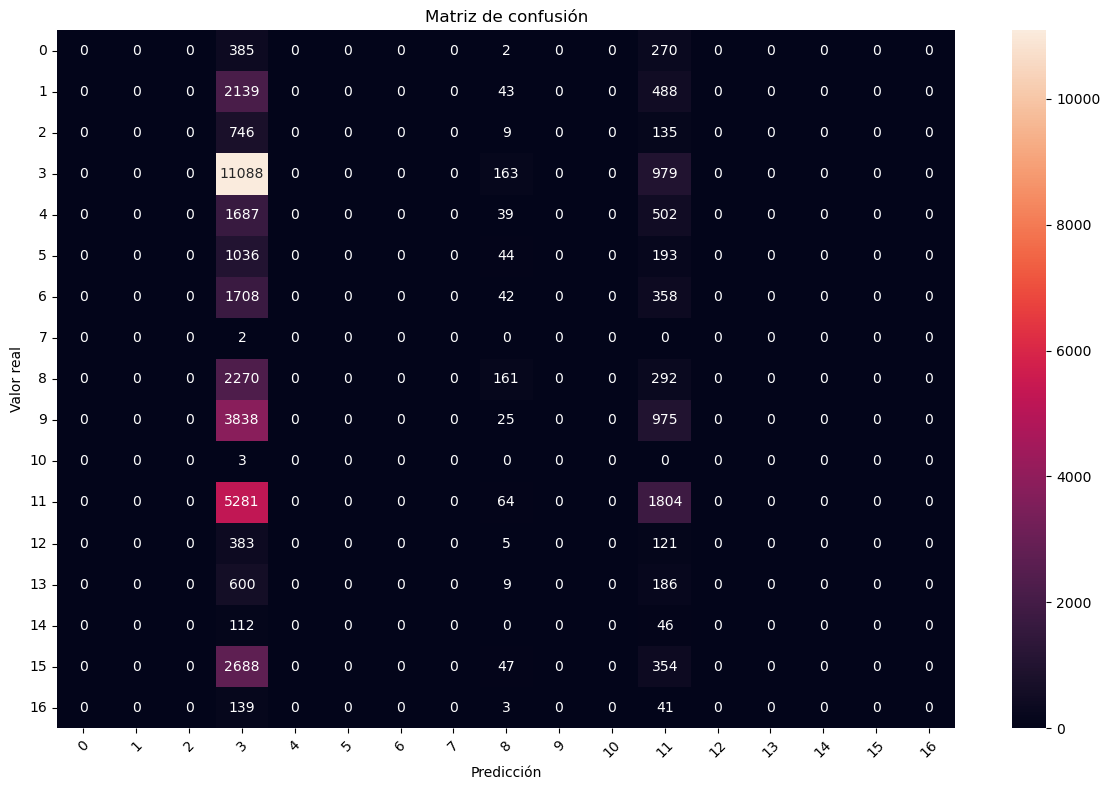

In [95]:
#Evaluación de Random Forest

y_pred_rf = pipeline_rf.predict(Xtest)

accuracy_rf = accuracy_score(ytest, y_pred_rf)
print(f"Accuracy: {accuracy_rf:.4f}")

print(classification_report(ytest, y_pred_rf, zero_division=0))

cm = confusion_matrix(ytest, y_pred_rf)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Seguimos viendo el desbalanceo de clases y en este caso los datos han empeorado.

KNN

In [120]:
from sklearn.neighbors import KNeighborsClassifier

In [121]:
knn = KNeighborsClassifier()

In [122]:
preprocess_knn = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "dias_desde_publicacion"])])

In [123]:
Xtrain_listo_knn = preprocess_knn.fit_transform(Xtrain)
Xtest_listo_knn = preprocess_knn.transform(Xtest)

In [124]:
pipeline_knn = Pipeline(steps=[('preprocesamiento', preprocess_knn),
                              ('modelo', knn)])

In [125]:
pipeline_knn.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'dias_desde_publicacion'])])),
                ('modelo', KNeighborsClassifier())])

Accuracy: 0.3403
              precision    recall  f1-score   support

           0       0.11      0.18      0.13       657
           1       0.21      0.28      0.24      2670
           2       0.21      0.22      0.21       890
           3       0.41      0.58      0.48     12230
           4       0.25      0.17      0.20      2228
           5       0.19      0.08      0.12      1273
           6       0.27      0.24      0.25      2108
           7       0.00      0.00      0.00         2
           8       0.34      0.24      0.28      2723
           9       0.36      0.32      0.34      4838
          10       0.00      0.00      0.00         3
          11       0.32      0.27      0.29      7149
          12       0.31      0.14      0.19       509
          13       0.20      0.09      0.13       795
          14       0.61      0.27      0.38       158
          15       0.35      0.22      0.27      3089
          17       0.25      0.05      0.09       183

    accur

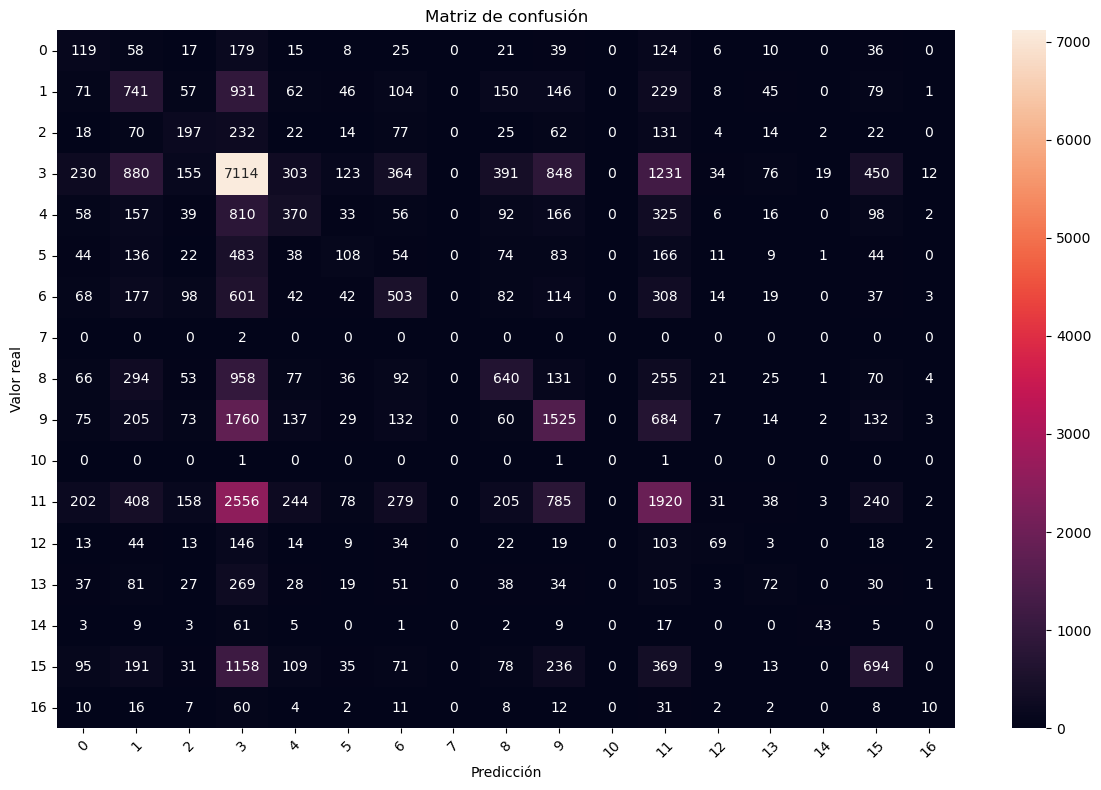

In [126]:
#Evaluación de KNN

y_pred_knn = pipeline_knn.predict(Xtest)

accuracy_knn = accuracy_score(ytest, y_pred_knn)
print(f"Accuracy: {accuracy_knn:.4f}")

print(classification_report(ytest, y_pred_knn, zero_division=0))

cm = confusion_matrix(ytest, y_pred_knn)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos que aquí el modelo acierta más y aunque sigue teniendo la misma tendencia, los datos de aciertos en distintas variables están más repartidos.

SVM

In [129]:
from sklearn.svm import SVC

In [130]:
svm = SVC()

In [131]:
preprocess_svm = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "dias_desde_publicacion"])])

In [132]:
Xtrain_listo_svm = preprocess_svm.fit_transform(Xtrain)
Xtest_listo_svm = preprocess_svm.transform(Xtest)

In [133]:
pipeline_svm = Pipeline(steps=[('preprocesamiento', preprocess_svm),
                              ('modelo', svm)])

In [ ]:
pipeline_svm.fit(Xtrain, ytrain)

In [ ]:
#Evaluación de SVM

y_pred_svm = pipeline_svm.predict(Xtest)

accuracy_svm = accuracy_score(ytest, y_pred_svm)
print(f"Accuracy: {accuracy_svm:.4f}")

print(classification_report(ytest, y_pred_svm, zero_division=0))

cm = confusion_matrix(ytest, y_pred_svm)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

NameError: name 'pipeline_svm' is not defined

**Predecir el número de likes**

**Encontrar grupos en los vídeos mediante diversas técnicas de clusterización**

**Crear un recomendador**

""title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador

[('title', 'string'), 
 ('channel_title', 'string'),
 ('pais', 'string'),
 ('views', 'int'),
 ('tags', 'string'),
 ('likes', 'int'),
 ('dislikes', 'int'),
 ('comment_count', 'int'),
 ('comments_disabled', 'boolean'),
 ('ratings_disabled', 'boolean'),
 ('video_error_or_removed', 'boolean'),
 ('description', 'string'),
 ('category', 'string'),
 ('month_trending', 'int'),
 ('month_publish', 'int')]"""
 • ¿Estás clasificando categorías? Usa Regresión Logística, Árboles de decisión, KNN o SVM.
• ¿Estás prediciendo un número? Usa Regresión Lineal o Árboles de decisión (Regresores).
• ¿Tus datos no tienen etiquetas (no sabes la respuesta)? Usa Clustering o Reducción de dimensionalidad.